In [13]:
import os
from prepare_data import process_all_folds

# Using the Fold 5 training file as a sentinel to check if the data preparation has already run
file_sentinel = "data/MSLR-WEB10K/Fold5/train_clean.txt"

if not os.path.exists(file_sentinel):
    print("Clean data not found. Starting extraction from raw SVM-Rank files...")
    process_all_folds(base_dataset_dir="data/MSLR-WEB10K", num_folds=5)
else:
    print("Data already formatted and ready for training. Data preparation step skipped.")

Data already formatted and ready for training. Data preparation step skipped.


In [ ]:
import json
import os
import multiprocessing as mp
from utils import run_experiment

RESULTS_FILE = "final_results.json"

# check if the results have already been saved
if os.path.exists(RESULTS_FILE):
    print(f"File '{RESULTS_FILE}' found! Loading results...")
    with open(RESULTS_FILE, "r") as f:
        final_results = json.load(f)
    print("Results successfully loaded from disk. Training skipped.\n")

else:
    print("No saved results found. Starting experiment training...\n")
    
    experiments = [
        {"name": "Baseline (GBDT no EFB)", "use_goss": False, "use_efb": False},
        {"name": "Solo EFB", "use_goss": False, "use_efb": True},
        {"name": "Solo GOSS", "use_goss": True, "use_efb": False},
        {"name": "LightGBM (GOSS + EFB)", "use_goss": True, "use_efb": True},
    ]

    context = mp.get_context('spawn')
    manager = context.Manager()
    results_dict = manager.dict()

    for conf in experiments:
        p = context.Process(
            target=run_experiment, 
            args=(conf["name"], conf["use_goss"], conf["use_efb"], results_dict)
        )
        
        p.start()
        p.join()
        
        if p.exitcode != 0:
            print(f"Warning: Experiment '{conf['name']}' failed with OS code {p.exitcode}.")
        else:
            print(f"--- Process for '{conf['name']}' closed successfully. ---\n")

    # convert the managed dictionary to a standard Python dictionary
    final_results = dict(results_dict)
    
    # save the results to a JSON file
    with open(RESULTS_FILE, "w") as f:
        json.dump(final_results, f, indent=4)
        
    print(f"\nTraining completed. Results saved in '{RESULTS_FILE}'.")

No saved results found. Starting experiment training...


Start experiment: Baseline (GBDT no EFB)
[LightGBM] [Info] Calculating query boundaries...
[LightGBM] [Info] Construct bin mappers from text data time 0.87 seconds
[200]	valid's ndcg@1: 0.493824	valid's ndcg@3: 0.483009	valid's ndcg@5: 0.488243	valid's ndcg@10: 0.507159	test's ndcg@1: 0.488681	test's ndcg@3: 0.480484	test's ndcg@5: 0.487904	test's ndcg@10: 0.504761
[400]	valid's ndcg@1: 0.497524	valid's ndcg@3: 0.483577	valid's ndcg@5: 0.489917	valid's ndcg@10: 0.508278	test's ndcg@1: 0.486748	test's ndcg@3: 0.484474	test's ndcg@5: 0.490159	test's ndcg@10: 0.507503
[600]	valid's ndcg@1: 0.496614	valid's ndcg@3: 0.482496	valid's ndcg@5: 0.491357	valid's ndcg@10: 0.508433	test's ndcg@1: 0.490695	test's ndcg@3: 0.48394	test's ndcg@5: 0.487326	test's ndcg@10: 0.506638
[800]	valid's ndcg@1: 0.494743	valid's ndcg@3: 0.48197	valid's ndcg@5: 0.489506	valid's ndcg@10: 0.507438	test's ndcg@1: 0.485081	test's ndcg@3: 0.482164	test's ndcg@5

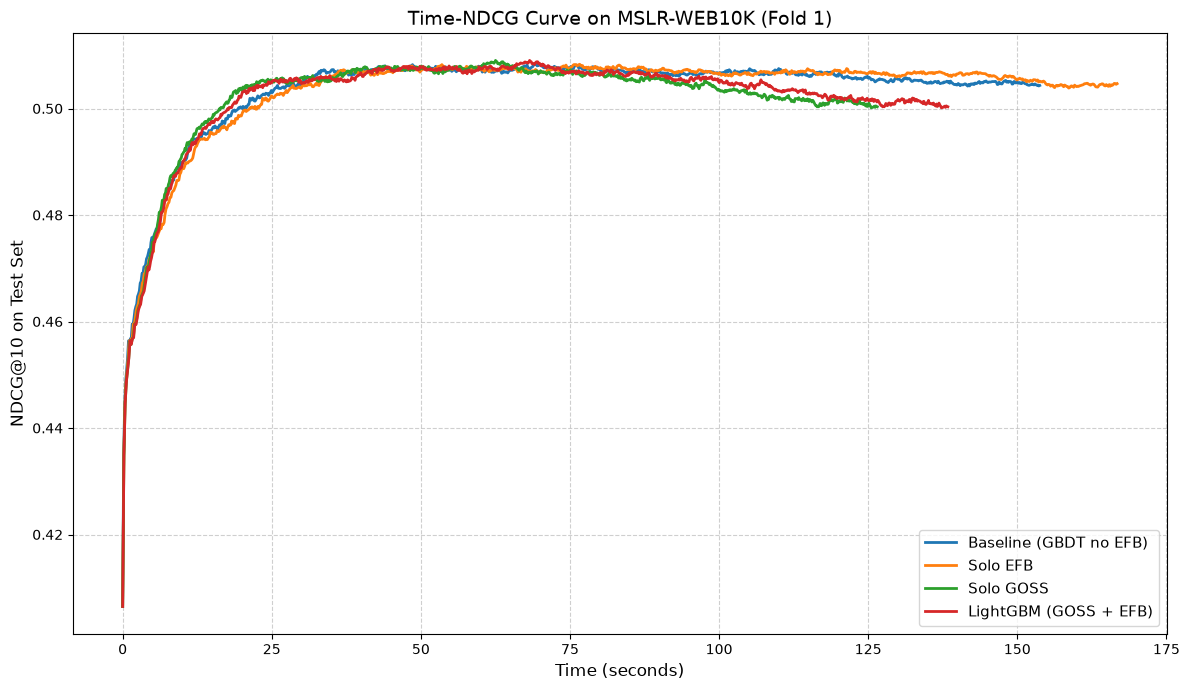

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Extract data (assuming final_results is already defined)
experiment_names = list(final_results.keys())

plt.figure(figsize=(12, 7))

# chart 1: Time-NDCG curve 
for name in experiment_names:
    ndcg_history = final_results[name]["ndcg_history"]
    time_history = final_results[name]["time_history"]
    
    # x-axis: cumulative time in seconds, y-axis: NDCG@10
    plt.plot(time_history, ndcg_history, label=name, linewidth=2.0)

plt.title("Time-NDCG Curve on MSLR-WEB10K (Fold 1)", fontsize=14)
plt.xlabel("Time (seconds)", fontsize=12)
plt.ylabel("NDCG@10 on Test Set", fontsize=12)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


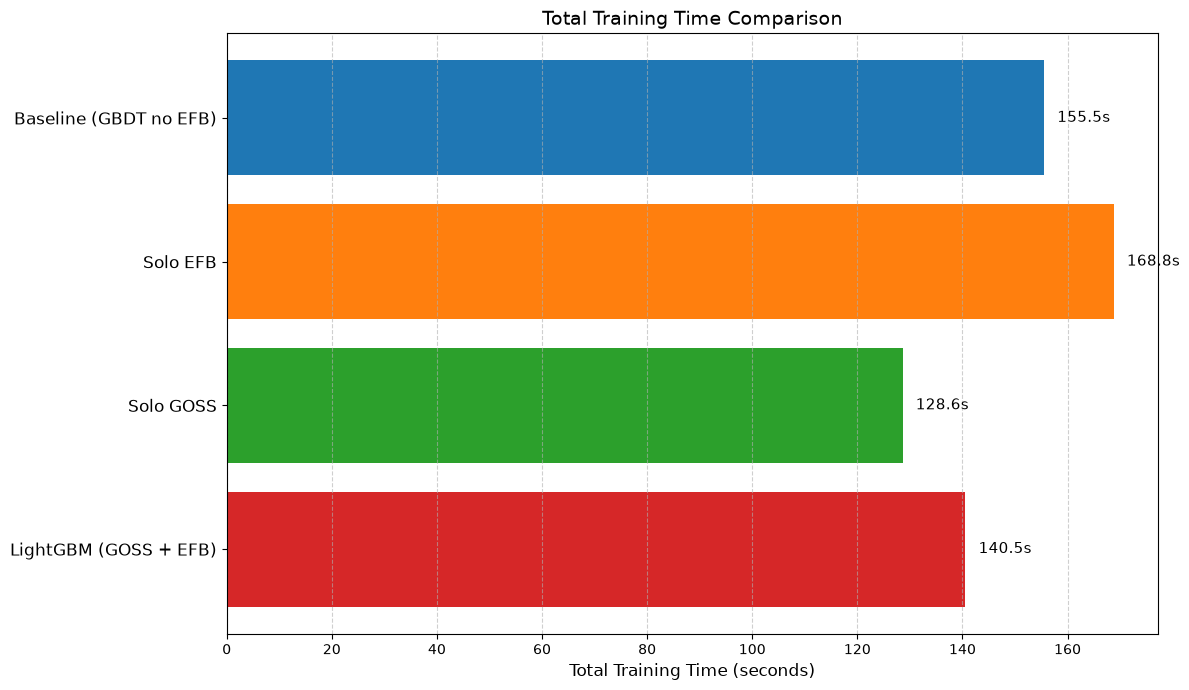

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# extract training times for each experiment
experiment_names = list(final_results.keys())
times = [final_results[name]["time"] for name in experiment_names]

plt.figure(figsize=(12, 7))

# chart 2: training time comparison
y_pos = np.arange(len(experiment_names))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# make sure there are enough colors if there are more than 4 experiments
if len(experiment_names) > len(colors):
    colors = plt.cm.tab10(np.linspace(0, 1, len(experiment_names)))

bars = plt.barh(y_pos, times, color=colors)
plt.yticks(y_pos, experiment_names, fontsize=12)
plt.gca().invert_yaxis() # invert the y-axis to have the first one on top
plt.xlabel("Total Training Time (seconds)", fontsize=12)
plt.title("Total Training Time Comparison", fontsize=14)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)

# add text labels at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + max(times)*0.015, bar.get_y() + bar.get_height()/2, 
             f'{width:.1f}s', ha='left', va='center', fontsize=11)

plt.tight_layout()
plt.show()